<a href="https://colab.research.google.com/github/ubaldinho/Hello_World/blob/main/PW2_PGD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGD Attack

In this section, we show how to perform a patch attack using the Projected Gradient Descent (PGD) method on a classification model. The ultimate goal is to craft a patch that can be pasted onto a panel sign to change the model's prediction.

Import all required libraries for this practical work:

In [3]:
from src.data import GTSRB
from torch import nn
import torch
import matplotlib.pyplot as plt
import numpy as np

The following cell loads the GTSRB dataset and a pre-trained ResNet-18 model architecture. It then modifies the final fully connected layer of the model to have 42 output features, corresponding to the 42 classes in the GTSRB dataset.

Load the weights from the trained model file ``model_gtsrb.pth`` using PyTorch’s recommended method for inference. See the official documentation: https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference


In [4]:
train_set, test_set = GTSRB()
model = torch.hub.load('pytorch/vision', 'resnet18', weights=None)
model.fc = nn.Linear(model.fc.in_features, 43)

# TODO : (a) Load the weights of the trained model

model.load_state_dict(torch.load("/content/model_gtsrb.pth"))

100%|██████████| 187M/187M [00:10<00:00, 17.4MB/s]
100%|██████████| 89.0M/89.0M [00:05<00:00, 17.7MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 220kB/s]


Downloading: "https://github.com/pytorch/vision/zipball/main" to /root/.cache/torch/hub/main.zip


<All keys matched successfully>

This cell defines and prints the labels of the GTSRB dataset. The dataset contains 42 classes, each representing a different type of traffic sign.

In [5]:
gtsrb_labels = [
    '20_speed',
    '30_speed',
    '50_speed',
    '60_speed',
    '70_speed',
    '80_speed',
    '80_lifted',
    '100_speed',
    '120_speed',
    'no_overtaking_general',
    'no_overtaking_trucks',
    'right_of_way_crossing',
    'right_of_way_general',
    'give_way',
    'stop',
    'no_way_general',
    'no_way_trucks',
    'no_way_one_way',
    'attention_general',
    'attention_left_turn',
    'attention_right_turn',
    'attention_curvy',
    'attention_bumpers',
    'attention_slippery',
    'attention_bottleneck',
    'attention_construction',
    'attention_traffic_light',
    'attention_pedestrian',
    'attention_children',
    'attention_bikes',
    'attention_snowflake',
    'attention_deer',
    'lifted_general',
    'turn_right',
    'turn_left',
    'turn_straight',
    'turn_straight_right',
    'turn_straight_left',
    'turn_right_down',
    'turn_left_down',
    'turn_circle',
    'lifted_no_overtaking_general',
    'lifted_no_overtaking_trucks'
]

for i, label in enumerate(gtsrb_labels):
    print(f"{i} : {label}")

0 : 20_speed
1 : 30_speed
2 : 50_speed
3 : 60_speed
4 : 70_speed
5 : 80_speed
6 : 80_lifted
7 : 100_speed
8 : 120_speed
9 : no_overtaking_general
10 : no_overtaking_trucks
11 : right_of_way_crossing
12 : right_of_way_general
13 : give_way
14 : stop
15 : no_way_general
16 : no_way_trucks
17 : no_way_one_way
18 : attention_general
19 : attention_left_turn
20 : attention_right_turn
21 : attention_curvy
22 : attention_bumpers
23 : attention_slippery
24 : attention_bottleneck
25 : attention_construction
26 : attention_traffic_light
27 : attention_pedestrian
28 : attention_children
29 : attention_bikes
30 : attention_snowflake
31 : attention_deer
32 : lifted_general
33 : turn_right
34 : turn_left
35 : turn_straight
36 : turn_straight_right
37 : turn_straight_left
38 : turn_right_down
39 : turn_left_down
40 : turn_circle
41 : lifted_no_overtaking_general
42 : lifted_no_overtaking_trucks


This cell sets the model to evaluation mode and performs predictions on five images. It then displays the images together with their ground-truth labels and the model’s predicted labels.

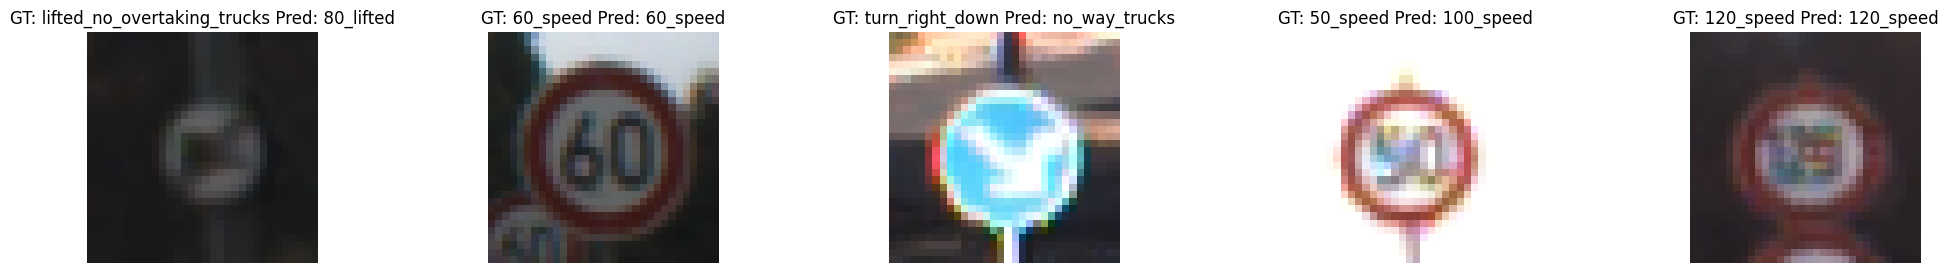

In [6]:
model.eval()

dataiter = iter(test_set)
for i in range(70):
    next(dataiter)
images, labels = next(dataiter)

# Get model predictions
outputs = model(images)
_, predicted = torch.max(outputs, 1)

# Show images with ground truth and predictions
fig, axes = plt.subplots(1, 5, figsize=(25, 3))
for i in range(5):
    ax = axes[i]
    ax.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))
    ax.set_title(f"GT: {gtsrb_labels[labels[i].item()]} Pred: {gtsrb_labels[predicted[i].item()]}")
    ax.axis('off')
plt.show()

This cell takes an image and passes it through the model to obtain a prediction for each class. It then applies the softmax function to convert the model’s output into probabilities. Finally, it plots a bar chart showing the model’s confidence for each class label corresponding to the selected image.

Plot the model’s confidence for the image of the 60 panel sign. Is the model confident that the image belongs to the ``60\_speed'' class?

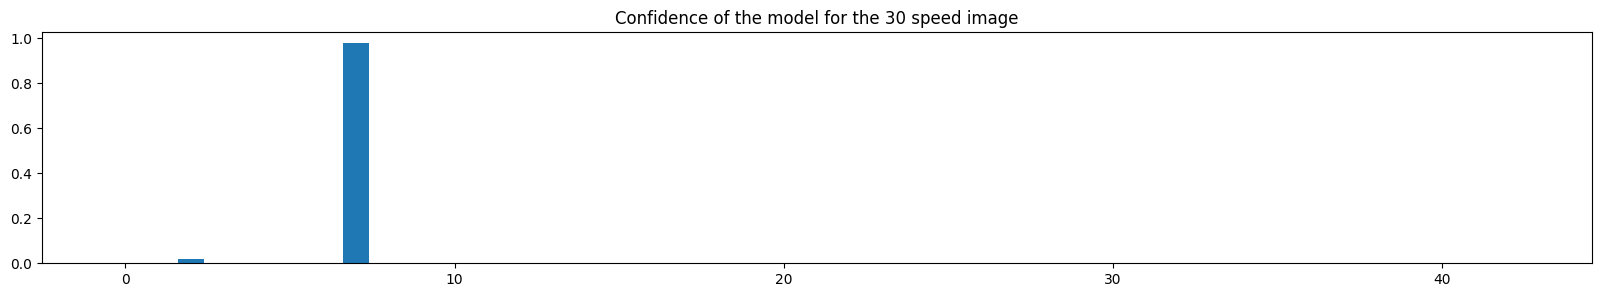

In [7]:
image = images[3].unsqueeze(0) # TODO : (c) Set the variable image as the 60 panel sign image using the tensor images. You may need to use .unsqueeze(0) to add a batch dimension
softmax = torch.nn.Softmax(dim=1)
proba = softmax(model(image).detach()).numpy()[0]
plt.figure(figsize=(20, 3))
plt.bar(list(range(43)), proba)
plt.title("Confidence of the model for the 30 speed image")
plt.show()

## Projected Gradient Descent in the whole image

In the following cell, we define the function ``Projected\_Gradient\_Descent,'' which generates an adversarial image using the Projected Gradient Descent (PGD) method. The function takes as input the number of steps, the image, and the target class. It then iteratively computes the following values:
$$
\hat{x}^{t+1} = \text{clip}_{\left[ x - \delta, x + \delta \right]} \left( \hat{x}^t - \epsilon \times \text{sign} \left( \nabla_{\hat{x}^t} J \left( \theta, \hat{x}^t, y^{\text{target}} \right) \right) \right)
$$
where $\hat{x}^t$ is the adversarial image at step $t$, $x$ is the original image, $\delta$ is the tolerance, $\epsilon$ is the step size, $J$ is the loss function, $\theta$ are the model parameters, and $y^{\text{target}}$ is the target class. The initialization is given by $\hat{x}^0 = x$.

Notice that this is exactly what we did for the targeted FGSM, with two main differences:
- it is iterative, allowing the algorithm to converge to a better adversarial image,
- and it adds a projection step to ensure that the adversarial image remains close to the original image.

The following code provides the implementation of this method:


In [8]:
def Projected_Gradient_Descent(step, image, target):
    tol = 0.04
    criterion = torch.nn.CrossEntropyLoss()
    original_image = image.detach()

    for i in range(step):
        image.requires_grad_()
        predicted = model(image)
        loss = criterion(predicted, target)
        loss.backward()

        perturbation = 0.01 * image.grad.sign()
        adversarial_image = torch.clamp(image - perturbation, original_image-tol, original_image+tol)
        image = adversarial_image.clamp_(0,1).detach()

        proba = softmax(model(image.clone()).detach()).numpy()[0]
        print(f"Step {i} - Confidence: {proba[target.item()]}")

    return image, perturbation

res, perturbation = Projected_Gradient_Descent(5, image, torch.tensor([5]))

Step 0 - Confidence: 0.0005202269530855119
Step 1 - Confidence: 0.011093538254499435
Step 2 - Confidence: 0.11981362104415894
Step 3 - Confidence: 0.5989557504653931
Step 4 - Confidence: 0.6820057034492493


In [9]:
predicted = model(image).argmax()
predicted_adv = model(res).argmax()

Show the result :

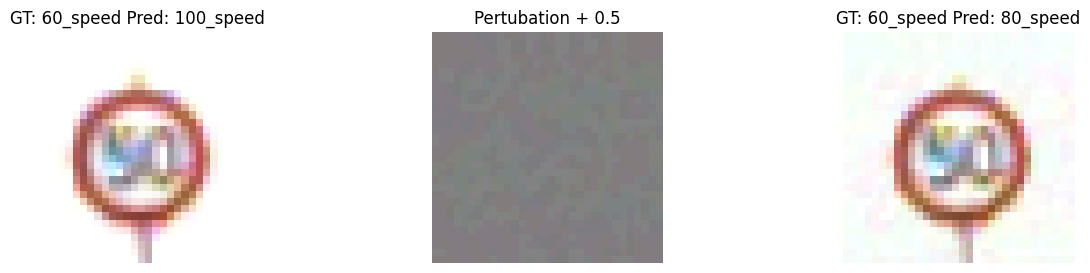

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
ax = axes[0]
ax.imshow(np.transpose(image.detach().numpy().squeeze(0), (1, 2, 0)))
ax.set_title(f"GT: {gtsrb_labels[labels[1].item()]} Pred: {gtsrb_labels[predicted.item()]}")
ax.axis('off')
ax = axes[1]
ax.imshow(np.transpose((perturbation)[0].detach().cpu().numpy(), (1, 2, 0)) + 0.5)
ax.set_title(f"Pertubation + 0.5")
ax.axis('off')
ax = axes[2]
ax.imshow(np.transpose(res.detach().numpy().squeeze(0), (1, 2, 0)))
ax.set_title(f"GT: {gtsrb_labels[labels[1].item()]} Pred: {gtsrb_labels[predicted_adv.item()]}")
ax.axis('off')
plt.show()

Show the corresponding confidence :

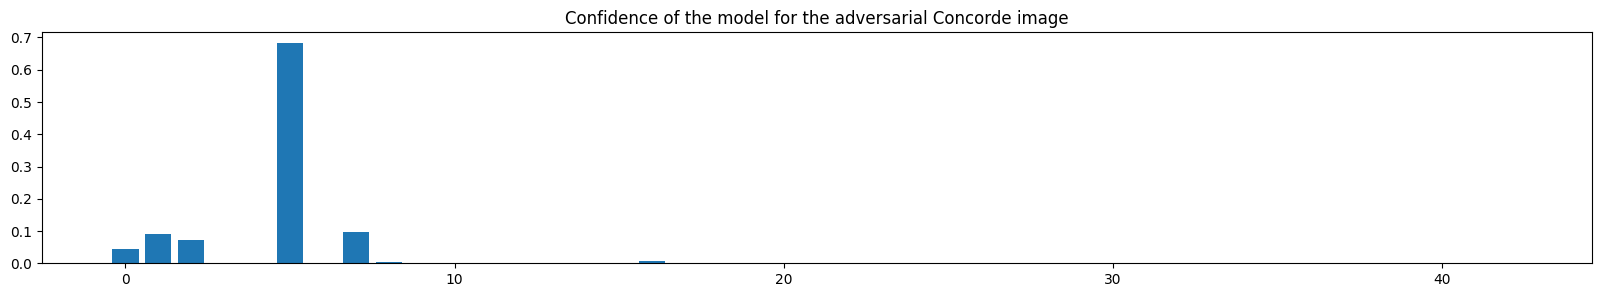

In [11]:
proba = softmax(model(res).detach()).numpy()[0]
plt.figure(figsize=(20, 3))
plt.bar(list(range(43)), proba)
plt.title("Confidence of the model for the adversarial Concorde image")
plt.show()

## Patch Attack using PGD

To achieve our goal, we use the Projected Gradient Descent (PGD) attack. Unlike FGSM, which performs a single step, the PGD attack uses multiple steps directed toward the targeted label. However, since we do not have direct access to the model, we aim to craft a patch (a small square) that can be pasted onto the panel without covering the number 60, ensuring that the sign remains readable by humans and does not arouse suspicion.

You will implement the following equations:

\begin{equation}
    \hat{x}^{t+1} = \underbrace{(m \odot p^t)}_{\text{Patch part}} + \overbrace{((1-m) \odot x^0)}^{\text{Rest of the image}}
\end{equation}

\begin{equation}
        z^{t+1} = m \odot \text{sign} \left( \nabla_{p^t} J \left( \theta, \hat{x}^{t+1} ,y^\text{target} \right) \right)
\end{equation}

\begin{equation}
    p^{t+1} = \text{clip}_{\left[0,1\right]^n} \left( p^t - \epsilon \times z^{t+1} \right)
\end{equation}

where $x^0 = x$ and $p^0$ is a random patch.

Tips :
- $\nabla_{ p^t} J \left( \theta, \hat{x}^{t+1},y^{target} \right)$ can be computed using ```patch.grad```

In [12]:
from math import e
image = images[1].clone().detach().unsqueeze(0)

def Patch_Attack(step, image, target):
    criterion = torch.nn.CrossEntropyLoss()
    original_image = image.detach().clone()
    mask = torch.zeros_like(image)
    mask[0, :, 23:27, 7:25] = 1
    patch = torch.randn_like(image)

    confidence_target = 0
    i = 0
    epsilon = 0.01
    while(confidence_target < 0.8):
        patch.requires_grad_()
        adversarial_image = (original_image * (1 - mask)) + (patch * mask)
        predicted = model(adversarial_image) # TODO (d) : Define the adversarial image and give it to the model
        loss = criterion(predicted, target)
        loss.backward()

        perturbation = torch.sign(patch.grad) # TODO (e) : Define the perturbation
        patch = patch - epsilon * (mask * perturbation) # TODO (f) : Apply the perturbation to the patch
        patch = torch.clamp(patch, 0, 1).clone().detach()

        proba = softmax(model(((original_image*(1-mask)) + (patch*mask)).clone()).detach()).numpy()[0]
        confidence_target = proba[target.item()]
        print(f"Step {i} - Confidence: {proba[target.item()]}")
        i += 1

        if i == step:
            break

    return original_image, patch, mask

Show the result :

Step 0 - Confidence: 0.0005503866705112159
Step 1 - Confidence: 0.0013296467950567603
Step 2 - Confidence: 0.0027951905503869057
Step 3 - Confidence: 0.005339323077350855
Step 4 - Confidence: 0.009576738812029362
Step 5 - Confidence: 0.01665780320763588
Step 6 - Confidence: 0.027571070939302444
Step 7 - Confidence: 0.04256366565823555
Step 8 - Confidence: 0.0642087385058403
Step 9 - Confidence: 0.09689415246248245
Step 10 - Confidence: 0.14385442435741425
Step 11 - Confidence: 0.2166336327791214
Step 12 - Confidence: 0.30430129170417786
Step 13 - Confidence: 0.39403027296066284
Step 14 - Confidence: 0.4732382595539093
Step 15 - Confidence: 0.5375790596008301
Step 16 - Confidence: 0.5911480784416199
Step 17 - Confidence: 0.6420865654945374
Step 18 - Confidence: 0.6865517497062683
Step 19 - Confidence: 0.7313246130943298
Step 20 - Confidence: 0.7683594226837158
Step 21 - Confidence: 0.7980053424835205
Step 22 - Confidence: 0.8256518840789795


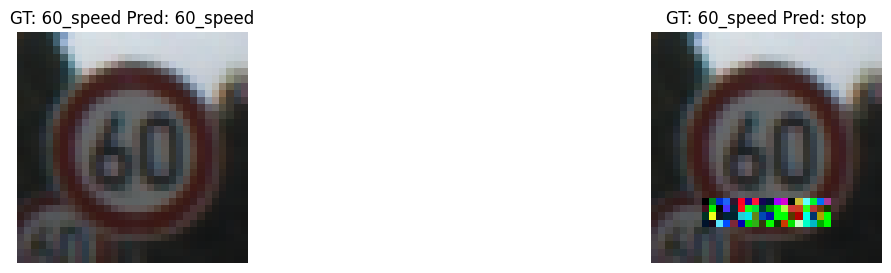

In [13]:
image, patch, mask = Patch_Attack(100, image, torch.tensor([14]))
res = (image * (1-mask)) + (patch * mask)
predicted = model(image).argmax()
predicted_adv = model(res).argmax()

fig, axes = plt.subplots(1, 2, figsize=(15, 3))
ax = axes[0]
ax.imshow(np.transpose(image.detach().numpy().squeeze(0), (1, 2, 0)))
ax.set_title(f"GT: {gtsrb_labels[labels[1].item()]} Pred: {gtsrb_labels[predicted.item()]}")
ax.axis('off')
ax = axes[1]
ax.imshow(np.transpose(res.detach().numpy().squeeze(0), (1, 2, 0)))
ax.set_title(f"GT: {gtsrb_labels[labels[1].item()]} Pred: {gtsrb_labels[predicted_adv.item()]}")
ax.axis('off')
plt.show()

Show the corresponding confidence :

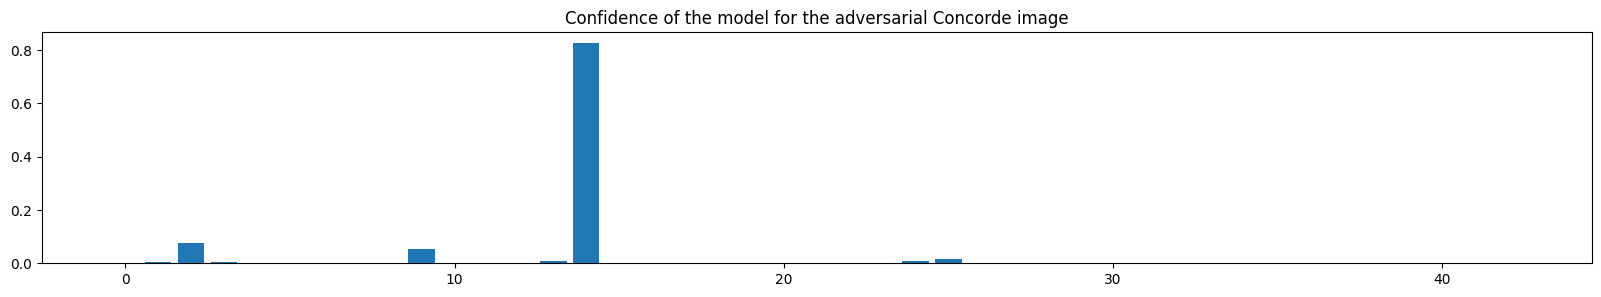

In [14]:
proba = softmax(model(res).detach()).numpy()[0]
plt.figure(figsize=(20, 3))
plt.bar(list(range(43)), proba)
plt.title("Confidence of the model for the adversarial Concorde image")
plt.show()